<a href="https://colab.research.google.com/github/shrutikushwaha2110-ux/Facial-Expression-Recognition-CNN/blob/exp%2Ftransfer-learning/04_transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import numpy as np

!unzip fer2013_preprocessed.npz.zip

Archive:  fer2013_preprocessed.npz.zip
  inflating: X_train.npy             
  inflating: y_train.npy             
  inflating: X_val.npy               
  inflating: y_val.npy               
  inflating: X_test.npy              
  inflating: y_test.npy              


In [10]:
import numpy as np

# Load the 6 individual .npy files directly from your workspace
X_train = np.load("X_train.npy")
y_train = np.load("y_train.npy")
X_val = np.load("X_val.npy")
y_val = np.load("y_val.npy")
X_test = np.load("X_test.npy")
y_test = np.load("y_test.npy")

print("Successfully loaded team's data from individual files!")
print(f"X_train shape: {X_train.shape}")
print(f"X_val shape:   {X_val.shape}")
print(f"X_test shape:  {X_test.shape}")

Successfully loaded team's data from individual files!
X_train shape: (22949, 48, 48, 1)
X_val shape:   (5749, 48, 48, 1)
X_test shape:  (7178, 48, 48, 1)


In [11]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# 1. Resize and prepare datasets for MobileNetV2 (_mb)
def prepare_mb_data(X):
    X_resized = tf.image.resize(X, (96, 96))
    X_rgb = tf.repeat(X_resized, repeats=3, axis=-1)
    return X_rgb

print("Preparing and resizing datasets...")
X_train_mb = prepare_mb_data(X_train)
X_val_mb = prepare_mb_data(X_val)
X_test_mb = prepare_mb_data(X_test)

# 2. Load MobileNetV2 base without top layers
base_model = MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze base layers first

# 3. Attach custom classification head using the Functional API
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
output_layer = Dense(7, activation='softmax')(x) # 7 emotion classes

model = Model(inputs=base_model.input, outputs=output_layer)

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# 4. Train the classification head
history_head = model.fit(
    X_train_mb, y_train,
    validation_data=(X_val_mb, y_val),
    epochs=10,
    batch_size=64
)

Preparing and resizing datasets...


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 48, 48,    │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 48, 48,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 48, 48,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 48, 48,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 48, 48,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 48, 48,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 49, 49,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 24, 24,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 24, 24,    │      2,304 │ block_1_depthwis

 Total params: 2,587,719 (9.87 MB)

 Trainable params: 329,735 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 34s 60ms/step - accuracy: 0.3596 - loss: 1.6506 - val_accuracy: 0.4321 - val_loss: 1.4941
Epoch 2/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.4151 - loss: 1.5140 - val_accuracy: 0.4502 - val_loss: 1.4404
Epoch 3/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.4366 - loss: 1.4658 - val_accuracy: 0.4524 - val_loss: 1.4337
Epoch 4/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.4496 - loss: 1.4353 - val_accuracy: 0.4653 - val_loss: 1.3975
Epoch 5/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.4610 - loss: 1.4058 - val_accuracy: 0.4634 - val_loss: 1.3857
Epoch 6/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.4709 - loss: 1.3879 - val_accuracy: 0.4801 - val_loss: 1.3672
Epoch 7/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4775 - loss: 1.3647 - val_accuracy: 0.4790 - val_loss: 1.3714
Epoch 8/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.4808 - loss: 1.3467 - val_a

Starting fine-tuning with Early Stopping...
Epoch 1/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 37s 56ms/step - accuracy: 0.8994 - loss: 0.2878 - val_accuracy: 0.5147 - val_loss: 2.3535 - learning_rate: 1.0000e-04
Epoch 2/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9189 - loss: 0.2362 - val_accuracy: 0.5302 - val_loss: 2.4857 - learning_rate: 1.0000e-04
Epoch 3/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9339 - loss: 0.1968 - val_accuracy: 0.5100 - val_loss: 2.5802 - learning_rate: 1.0000e-04
Epoch 4/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9561 - loss: 0.1393 - val_accuracy: 0.5443 - val_loss: 2.5869 - learning_rate: 5.0000e-05
Epoch 5/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9650 - loss: 0.1105 - val_accuracy: 0.5523 - val_loss: 2.4820 - learning_rate: 5.0000e-05

Evaluating model on test data...
225/225 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step
Test Accuracy: 51.85%
Macro F1 Score: 0.4722

Classification Report:
              precision  

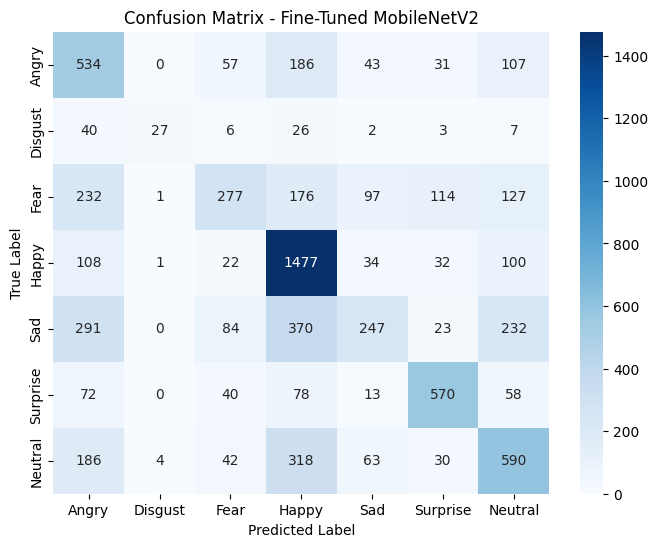

Model saved successfully!


In [13]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Unfreeze the MobileNetV2 base model for fine-tuning
base_model.trainable = True

# Keep lower layers frozen, fine-tune only the top 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# 2. Recompile with a low learning rate
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Set up smart restrictions (Callbacks)
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,               # Stop if val_loss doesn't improve for 4 epochs
    restore_best_weights=True # Keep the weights from the absolute best epoch
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,               # Cut learning rate in half if it plateaus
    patience=2,               # Wait 2 epochs before reducing LR
    min_lr=0.00001
)

print("Starting fine-tuning with Early Stopping...")
# 4. Fine-tune for up to 15 epochs (will stop early if it stops improving)
history_fine = model.fit(
    X_train_mb, y_train,
    validation_data=(X_val_mb, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr]
)

# 5. Evaluate on the Test Set
print("\nEvaluating model on test data...")
y_pred_probs = model.predict(X_test_mb)
y_pred = np.argmax(y_pred_probs, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro F1 Score: {macro_f1:.4f}")

# Classification Report
print("\nClassification Report:")
emotion_labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
print(classification_report(y_test, y_pred, target_names=emotion_labels))

# 6. Plot Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=emotion_labels, yticklabels=emotion_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Fine-Tuned MobileNetV2')
plt.show()

# 7. Save final model
model.save('/content/fer2013_mobilenet_finetuned_best.keras')
print("Model saved successfully!")